In [23]:
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()

llm = ChatGoogleGenerativeAI(model="gemini-3-flash-preview")

## Orchestrator-worker

The **orchestrator-worker** pattern is useful when a user request contains multiple independent or semi-independent pieces of work. The orchestrator breaks the request into smaller tasks, workers execute those tasks, and a collector combines the results into one final response.

### How it works

1. The user query is stored in the shared graph state.
2. The orchestrator asks the language model to create a list of tasks.
3. A worker executes each task and produces an individual result.
4. The collector summarizes the worker results.
5. LangGraph passes the updated state between these nodes until the workflow finishes.

This pattern is a good fit for research assistants, document analysis, comparison workflows, and other applications where a large request can be divided into smaller operations. Independent tasks can also be executed in parallel to reduce latency.

#### Creating the llm structured output

The structured output model defines the format expected from the orchestrator. Here, the language model must return a `tasks` list, which makes its response predictable and easy for the worker node to consume.

In [24]:
from pydantic import BaseModel, Field
from typing import TypedDict, List

class llm_schema(BaseModel):
    tasks: List[str] = Field(..., description="A list of tasks to be performed by the worker.")

llm_with_schema = llm.with_structured_output(llm_schema)

#### Creating the graph schema

In [25]:
class graph_schema(TypedDict):
    query: str
    tasks: List[str]
    results: List[str]
    summary: str

#### Creating the Orchestrator node

The orchestrator node is used for **planning and task decomposition**. It reads the user query and asks the model to split it into smaller prompts. Use this node when a request needs multiple operations, such as finding facts about several subjects or analyzing multiple documents separately.

In [26]:
from langchain_core.prompts import ChatPromptTemplate

def orchestrator_node(state: graph_schema) -> graph_schema:

    user_query = state['query']

    prompt = ChatPromptTemplate.from_messages([
        "system", "You are an orchestrator that breaks down a user query into tasks for the worker.",
        "user", "User query: {query}. Please generate one prompt per task for the worker to complete. Return the tasks in a list format.",   
    ])

    chain = prompt | llm_with_schema

    response = chain.invoke({"query": user_query})

    state["tasks"] = response.tasks

    return state

#### Executable Function

The execution function is the worker's reusable unit of work. It receives one task, sends it to the language model, and returns the generated content. Keeping this logic separate makes it easy to run the same operation for every task.

In [27]:
def execute(query:str):

    response = llm.invoke(f"Please execute this task {query}")
    return response.content

#### Worker Node

The worker node is used for **performing the planned tasks**. It reads the task list, executes each task with `ThreadPoolExecutor`, and stores the individual responses. Parallel execution is useful when tasks are independent and each task may involve a relatively slow model or external API call.

In [28]:
from concurrent.futures import ThreadPoolExecutor

def worker_node(state: graph_schema) -> graph_schema:

    tasks = state['tasks']
    results = []

    with ThreadPoolExecutor(max_workers=len(tasks)) as executor:

        results_futures = executor.map(execute, tasks)
        for result in results_futures:
            results.append(result)
    
    state['results'] = results
    
    return state

#### Collector Node

The collector node is used for **combining and presenting the results**. It reads all worker responses and asks the language model to produce one concise summary. This is useful when the user should receive a single coherent answer instead of several separate worker outputs.

In [29]:
def collector_node(state: graph_schema) -> graph_schema:

    results = state['results']

    prompt = ChatPromptTemplate.from_messages(
        [
            ("system", "You are a collector that summarizes the results from the worker."),
            ("user", "Here are the results from the worker: {results}. Please summarize these results in a concise manner."),
        ]
    )

    chain = prompt | llm

    summary = chain.invoke({"results": results})

    state['summary'] = summary.content

    return state

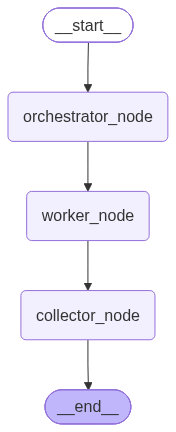

In [30]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node("orchestrator_node", orchestrator_node)
graph.add_node("worker_node", worker_node)
graph.add_node("collector_node", collector_node)

graph.add_edge(START, "orchestrator_node")
graph.add_edge("orchestrator_node", "worker_node")
graph.add_edge("worker_node", "collector_node")
graph.add_edge("collector_node", END)

orchestrator_graph = graph.compile()

from IPython.display import Image

Image(orchestrator_graph.get_graph().draw_mermaid_png())

In [31]:
orchestrator_graph.invoke({
    'query': "What is the capital of France and the population of France? And also what is LangGraph?",
    'tasks': [],
    'results': [],
    'summary': ""
})

{'query': 'What is the capital of France and the population of France? And also what is LangGraph?',
 'tasks': ['Identify the capital city of France.',
  'Provide the current population of France based on the most recent available data.',
  'Explain what LangGraph is and its purpose in the context of building applications with large language models.'],
 'results': [[{'type': 'text',
    'text': 'The capital city of France is **Paris**.',
    'extras': {'signature': 'EvcBCvQBAWkUfROayuSeSFuGy+Omu7Yn4kTrBQ+sBLtEJC5o58woqIG0h28/ZzIzHT1zITkFECaIwqA0rjNh9h0s/8ndNahdDOJWNsvUS6SSmF9IA7xSIEQhkQss0TqdZMYaLEFVvQe3T97Ius05wAlq5uIBH4j8vF6mlfKvl7lL/Teyji3OtfW1hC12mcHfSUz7HIQWhkUeJvIHtzDF7pFFG0cB7myzLcFWDya4a6xud/GKcd4I2ppxe37a+KU0x8b7cDsKeU2Ybk6ykXuVuD6ODGuie1GmexnDam1jcVdOx5lu8Ema/a5h0Eb3Bb41fmuc6RcTys2PKA=='}}],
  [{'type': 'text',
    'text': 'As of the most recent official data from **INSEE** (the National Institute of Statistics and Economic Studies), the population of France is estimated as f